# Brief introduction to Julia

[Julia](https://julialang.org) is a modern high-level programming language developed specifically with scientific computing in mind. We will briefly introduce Julia and demonstrate some of its design principles. This introduction is aimed at students of numerical analysis with previous programming experience.


## Further information on running this notebook

This notebook was set up and tested with Julia v1.9.3 but may also work with other versions.

*Note:* If you change a variable in a later cell and then re-execute an earlier cell, the results might change unexpectedly. Thus if in doubt, re-run the entire notebook *in order*. The reason is that all cells in a Jupyter notebooks share a common variable space.

*Note:* This notebook is tested using Firefox. Most parts should also work for other browsers such as Chrome.


## Authors and license

This material is distributed by Hendrik Ranocha under the MIT license. It is inspired by and partially derived from the talks
- [Robin Deits (2020), Intro to Julia Programming Language with Detroit Tech Watch](https://www.youtube.com/watch?v=qLO-yaUkLKE)
- [Hendrik Ranocha (2021), Introduction to Julia and Trixi, a numerical simulation framework for hyperbolic PDEs](https://github.com/trixi-framework/talk-2021-Introduction_to_Julia_and_Trixi)
- [Hendrik Ranocha and Michael Schlottke-Lakemper (2021), Tutorial on Trixi.jl at ICOSAHOM](https://github.com/trixi-framework/tutorial-2021-icosahom)

In [1]:
# Install all dependencies used in this talk
using Pkg
Pkg.activate(".")
Pkg.instantiate()

  Activating project at `c:\julialab\Julia_intro\RSEinJulia_02_Intro_Julia\RSEinJulia_02_Intro_Julia`


In [2]:
ENV["COLUMNS"] = 100 # display width

100

# Introduction to Julia

- [julialang.org](https://julialang.org)
- Julia is a high-level language like Python/Matlab with the performance of a fast language like C/C++/Fortran
- Julia is designed for scientific computing...
  - N-dimensional arrays
  - Reproducibility
- ...and valuable for general programming
  - Growing ecosystem of packages
  - Rich type system
- Encourages good software development practices

## Julia at a glance

- First public release in 2012, version 1.0 released in 2018
- Free
  - Julia itself is MIT licensed
  - It bundles some GPLed libraries (which can be disabled if desired)
- Built-in JIT compiler transforms Julia code to native assembly at run time
  - Uses LLVM under the hood
- Garbage collected
- Dynamically typed
- Organized via multiple dispatch

## A brief tour of Julia

### The basics

In [3]:
# Arithmetic
1 + 2

3

In [4]:
# Strings
println("Hello world")

Hello world


In [5]:
# Arrays
x = [1, 2, 3]
sum(x)

6

### Unicode

In [11]:
# type `\beta` + TAB
β = π / 4
tan(β) ≈ sin(β) / cos(β)

true

[ Info: Precompiling IJuliaExt [388d8a6b-6fe4-50b5-a981-2e7a5d676f34]
Precompiling packages...
   2.0 s  ✓ IJuliaExt (serial)
  1 dependency successfully precompiled in 2 seconds
[ Info: Precompiling IJuliaExt [6e0e26ac-fb43-584e-b323-fdbabcf95812]
Precompiling packages...
   3.0 s  ✓ IJuliaExt (serial)
  1 dependency successfully precompiled in 3 seconds


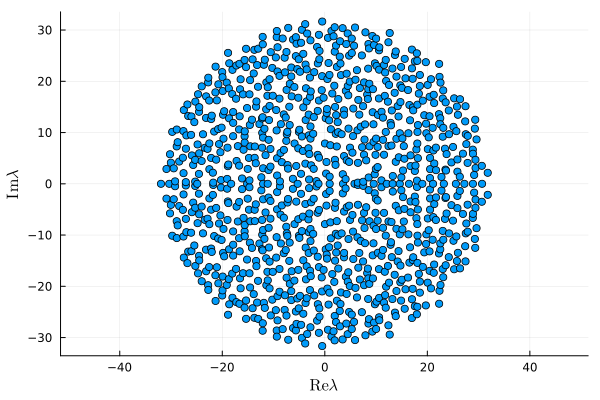

In [3]:
using LinearAlgebra, Plots, LaTeXStrings
n = 1_000
λ = eigvals(randn(n, n))
scatter(real(λ), imag(λ), aspect_ratio=:equal, legend=nothing,
        xguide=L"\operatorname{Re} \lambda", yguide=L"\operatorname{Im} \lambda")

### Functions

In [13]:
function say_hello(to_whom)
    println("Hello ", to_whom)
end

say_hello (generic function with 1 method)

In [14]:
say_hello("world")

Hello world


Functions are generic, so you can pass everything that works (duck typing)

In [15]:
say_hello([1, 2, 3])

Hello [1, 2, 3]


### Types

Everything in Julia has a type

In [16]:
typeof(1)

Int64

In [17]:
typeof(1.0)

Float64

In [18]:
typeof(π)

Irrational{:π}

In [19]:
typeof([1, 2, 3])

Vector{Int64} (alias for Array{Int64, 1})

In [20]:
typeof(1:3)

UnitRange{Int64}

In [21]:
x = range(0.0, 5.0, length = 10)
@show typeof(x)
@show length(x)
@show sum(x)
x

typeof(x) = StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}
length(x) = 10
sum(x) = 25.0


0.0:0.5555555555555556:5.0

You can create your own types easily

In [6]:
struct Person
    name::String
end

alice = Person("Alice")

Person("Alice")

User-defined types are as efficient as anything built-in

In [7]:
sizeof(Person) == sizeof(Ptr{String})

true

### Multiple dispatch

Julia does not use classes to organize nouns (types) and verbs (functions). Instead, multiple dispatch is a central design decision. Thus, the compiler chooses an appropriate method of a given function based on the types of all arguments (not their values!).

For more information, see [Stefan Karpinski's talk at JuliaCon (2019)](https://www.youtube.com/watch?v=kc9HwsxE1OY).

In [8]:
greet(x, y) = println(x, " greets ", y)

greet (generic function with 1 method)

In [9]:
alice = Person("Alice")
bob = Person("Bob")

greet(alice, bob)

Person("Alice") greets Person("Bob")


Currently there is only one greet() function, and it will work on `x` and `y` of any type:

In [10]:
greet(π, "Mainz")

π greets Mainz


We can use abstract types to organize the behavior of related types:

In [14]:
abstract type Animal end

struct Cat <: Animal
    name::String
end

We've already defined `greet(x, y)` for any `x` and `y`, but we can add another definition for a more specific set of input types.

We can be as specific or as general as we like with the argument types:

In [ ]:
greet(x::Person, y::Animal) = println(x, " pats ", y)

greet (generic function with 3 methods)

In [17]:
greet(x::Cat, y) = println(x, " meows at ", y)

greet (generic function with 3 methods)

Julia will always pick the *most specific* method that matches the provided function arguments.

In [18]:
fluffy = Cat("Fluffy")

greet(alice, fluffy)

Person("Alice") pats Cat("Fluffy")


In [19]:
greet(fluffy, alice)

Cat("Fluffy") meows at Person("Alice")


In [20]:
struct Dog <: Animal
    name::String
end

greet(x::Dog, y) = println(x, " barks at ", y)

greet(x::Dog, y::Person) = println("$x licks $y's face")

greet(x::Dog, y::Dog) = println("$x sniffs $y's butt")

greet (generic function with 6 methods)

In [21]:
fido = Dog("Fido")
rex = Dog("Rex")

greet(alice, fido)

Person("Alice") pats Dog("Fido")


In [22]:
greet(fido, fluffy)

Dog("Fido") barks at Cat("Fluffy")


In [23]:
greet(fido, bob)

Dog("Fido") licks Person("Bob")'s face


In [24]:
greet(fido, rex)

Dog("Fido") sniffs Dog("Rex")'s butt


If you want to know which `greet` method will be called for a given set of arguments, you can use `@which` to check:

In [25]:
@which greet(alice, fido)

greet(x::Person, y::Animal)
     @ Main In[15]:1

You can list all of the methods of a given function with `methods`:

In [26]:
methods(greet)

# 6 methods for generic function "greet" from Main:
 [1] greet(x::Dog, y::Dog)
     @ In[20]:9
 [2] greet(x::Dog, y::Person)
     @ In[20]:7
 [3] greet(x::Dog, y)
     @ In[20]:5
 [4] greet(x::Cat, y)
     @ In[17]:1
 [5] greet(x::Person, y::Animal)
     @ In[15]:1
 [6] greet(x, y)
     @ In[8]:1

You can access docstrings using `?`.

In [28]:
?methods

search: methods Method methodswith mesh3d! mesh3d hasmethod



```julia
methods(f, [types], [module])
```

Return the method table for `f`.

If `types` is specified, return an array of methods whose types match. If `module` is specified, return an array of methods defined in that module. A list of modules can also be specified as an array or set.

!!! compat "Julia 1.4"
    At least Julia 1.4 is required for specifying a module.


See also: [`which`](@ref), [`@which`](@ref Main.InteractiveUtils.@which) and [`methodswith`](@ref Main.InteractiveUtils.methodswith).


Tab completion works in Julia and can print possible signatures of functions.

In [ ]:
greet(     # type TAB 

LoadError: ParseError:
[90m# Error @ [0;0m]8;;file://c:/julialab/Julia_intro/RSEinJulia_02_Intro_Julia/RSEinJulia_02_Intro_Julia/In[40]#1:7\[90mIn[40]:1:7[0;0m]8;;\
greet([48;2;120;70;70m[0;0m   # type TAB
[90m#     └ ── [0;0m[91mExpected `)` or `,`[0;0m

## Modules

Modules in Julia are used to organize code into namespaces.

In [42]:
module MyUsefulModule

export hello

hello()   = println("Hello world")
goodbye() = println("Goodbye world")

end

MyUsefulModule.hello()

Hello world


The `using` command brings any `export`ed symbols from a module into the current namespace:

In [43]:
using .MyUsefulModule
hello()

Hello world


## Using packages

Julia has a built-in package manager called `Pkg`. It handles installing packages and managing all your package environments. 

A package *environment* represents a single set of installed packages. Let's activate the environment for this presentation:

In [44]:
using Pkg
Pkg.activate(".")
Pkg.instantiate()

  Activating project at `c:\julialab\Julia_intro\RSEinJulia_02_Intro_Julia\RSEinJulia_02_Intro_Julia`


(this is similar to `source venv/bin/activate` in a Python virtual environment)

We can install a package in our current environment. This will only affect that environment, so we can safely do this without breaking any other Julia projects we might be working on:

In [47]:
Pkg.add("BenchmarkTools")

     Project No packages added to or removed from `C:\julialab\Julia_intro\RSEinJulia_02_Intro_Julia\RSEinJulia_02_Intro_Julia\Project.toml`
    Manifest No packages added to or removed from `C:\julialab\Julia_intro\RSEinJulia_02_Intro_Julia\RSEinJulia_02_Intro_Julia\Manifest.toml`


The `Project.toml` file gives a concise description of the packages we've added to this environment:

In [50]:
println(read("Project.toml", String))

[deps]
BenchmarkTools = "6e4b80f9-dd63-53aa-95a3-0cdb28fa8baf"
LaTeXStrings = "b964fa9f-0449-5b57-a5c2-d3ea65f4040f"
LinearAlgebra = "37e2e46d-f89d-539d-b4ee-838fcccc9c8e"
Pkg = "44cfe95a-1eb2-52ea-b672-e2afdf69b78f"
Plots = "91a5bcdd-55d7-5caf-9e0b-520d859cae80"
Pluto = "c3e4b0f8-55cb-11ea-2926-15256bba5781"
PyCall = "438e738f-606a-5dbb-bf0a-cddfbfd45ab0"
SparseArrays = "2f01184e-e22b-5df5-ae63-d93ebab69eaf"



The package manager also generates a complete manifest of every package that is installed, including all the transitive dependencies and their versions. You can use this to reproduce a given package environment exactly:

In [55]:
foreach(println, first(readlines("Manifest.toml"), 10))

# This file is machine-generated - editing it directly is not advised

julia_version = "1.13.1"
manifest_format = "2.1"
project_hash = "638d798ea6e8624c7f41eda8bf9142adf4e061ad"

[[deps.AliasTables]]
deps = ["PtrArrays", "Random"]
git-tree-sha1 = "9876e1e164b144ca45e9e3198d0b689cadfed9ff"
registries = "General"


# Bonus features of Julia

## Anything can be a value

Julia has no special rules about what can or cannot be assigned to a variable or passed to a function. 

### Functions are values

A Julia function is a value like any other, so passing functions around and implementing higher-order functions is trivial. This approach is used in several higher order functions of Julia such as `mapreduce`.

In [56]:
data = randn(10^4)
sum(data) ≈ mapreduce(identity, +, data)

true

Functions can be inlined, even into standard library code. The compiler heuristics are often good and you can nudge it using `@inline` if necessary. Let's measure the performance of `mapreduce` with out own functions using `@benchmark` from BenchmarkTools:

In [57]:
using BenchmarkTools

my_identity(x) = x
my_plus(x, y) = x + y
@benchmark mapreduce($my_identity, $my_plus, $data)

BenchmarkTools.Trial: 10000 samples with 125 evaluations per sample.
 Range (min … max):  740.800 ns …  15.414 μs  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     744.800 ns               ┊ GC (median):    0.00%
 Time  (mean ± σ):   897.113 ns ± 602.292 ns  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █▂▂ ▁  ▁                        ▁                             ▁
  ██████▇██▇▇▆█▇▆▇▆▇▆▆▆▅▆▆▇▆▆▆▅▅▆▅█▆▆▇▆▆▅▆▅▅▅▆▄▄▄▅▆▅▄▅▃▄▄▃▃▄▄▅▄ █
  741 ns        Histogram: log(frequency) by time       2.84 μs <

 Memory estimate: 0 bytes, allocs estimate: 0.

If we tell the compiler not to inline our functions, the performance will be reduced significantly, of course.

In [58]:
@noinline my_identity_not_inlined(x) = x
@noinline my_plus_not_inlined(x, y) = x + y
@benchmark mapreduce($my_identity_not_inlined, $my_plus_not_inlined, $data)

BenchmarkTools.Trial: 10000 samples with 1 evaluation per sample.
 Range (min … max):  11.200 μs … 956.400 μs  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     11.400 μs               ┊ GC (median):    0.00%
 Time  (mean ± σ):   12.899 μs ±  12.758 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █▂▂▂       ▁▁       ▁             ▁          ▁   ▁           ▁
  ████▇▇▄▅▆▇███▄▄▄▃▄▄▃█▅█▄▄▄▃▁▃▃▄█▃▃█▄▄▄▅▁▃▁▄▁▅█▄▄▃█▄▃▃▄▆▃▁▁▃▇ █
  11.2 μs       Histogram: log(frequency) by time      33.9 μs <

 Memory estimate: 0 bytes, allocs estimate: 0.

### Types are values

Types can also be passed around as values and bound to variables with no special rules. This makes implementing factories or constructors easy:

In [59]:
zeros(Float64, 3, 3)

3×3 Matrix{Float64}:
 0.0  0.0  0.0
 0.0  0.0  0.0
 0.0  0.0  0.0

### Macros

A macro is written just like a normal Julia function. The difference is that a macro operates on the *expression* itself, not on its value:

`@show` : print out the *name* of a variable and its value. Great for quick debugging:

In [60]:
x = 5
@show x

x = 5


5

`@time` measure the elapsed time of an expression and return the result of that expression:

In [61]:
@time sqrt(big(π))

  0.000140 seconds (4 allocations: 400 bytes)


1.772453850905516027298167483341145182797549456122387128213807789852911284591025

We have seen its sibling `@benchmark` above.

`@printf` from the standard library `Printf` acts similarly to common printing in C:

In [62]:
using Printf
@printf("An integer %3d and a floating point number %.2f.", 5, 1.23456)

An integer   5 and a floating point number 1.23.